In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv
/kaggle/input/competitions/comment-category-prediction-challenge/train.csv
/kaggle/input/competitions/comment-category-prediction-challenge/test.csv


✅ All libraries imported.
✅ Fresh load. Train: (197999, 15) | Test: (102000, 14)
✅ NLTK WordNet lemmatizer available
⏳ Cleaning text (train + test)...
✅ Text cleaning done in 86.5s

--- Example cleanups ---
  ORIG:  She might be a bright spot for a party keou on Oahu dominated by greedy criminal
  CLEAN: she might be a bright spot for a party keou on oahu dominated by greedy criminal

  ORIG:  Under Alaska law, a non-tribal member is not bound to tribal court.. Living in a
  CLEAN: under alaska law a non tribal member is not bound to tribal court living in a pa

  ORIG:  in the future please spare me your strawman drivel, and if you can't manage an i
  CLEAN: in the future please spare me your strawman drivel and if you can't manage an in

✅ Features engineered. Train: (197999, 27) | Test: (102000, 26)
⏳ Computing word TF-IDF (35K, trigrams, no stop_words)...
✅ Word TF-IDF done in 99.1s → 35000 features
⏳ Computing char n-gram TF-IDF (25K)...
✅ Char TF-IDF done in 137.6s → 25000 featur

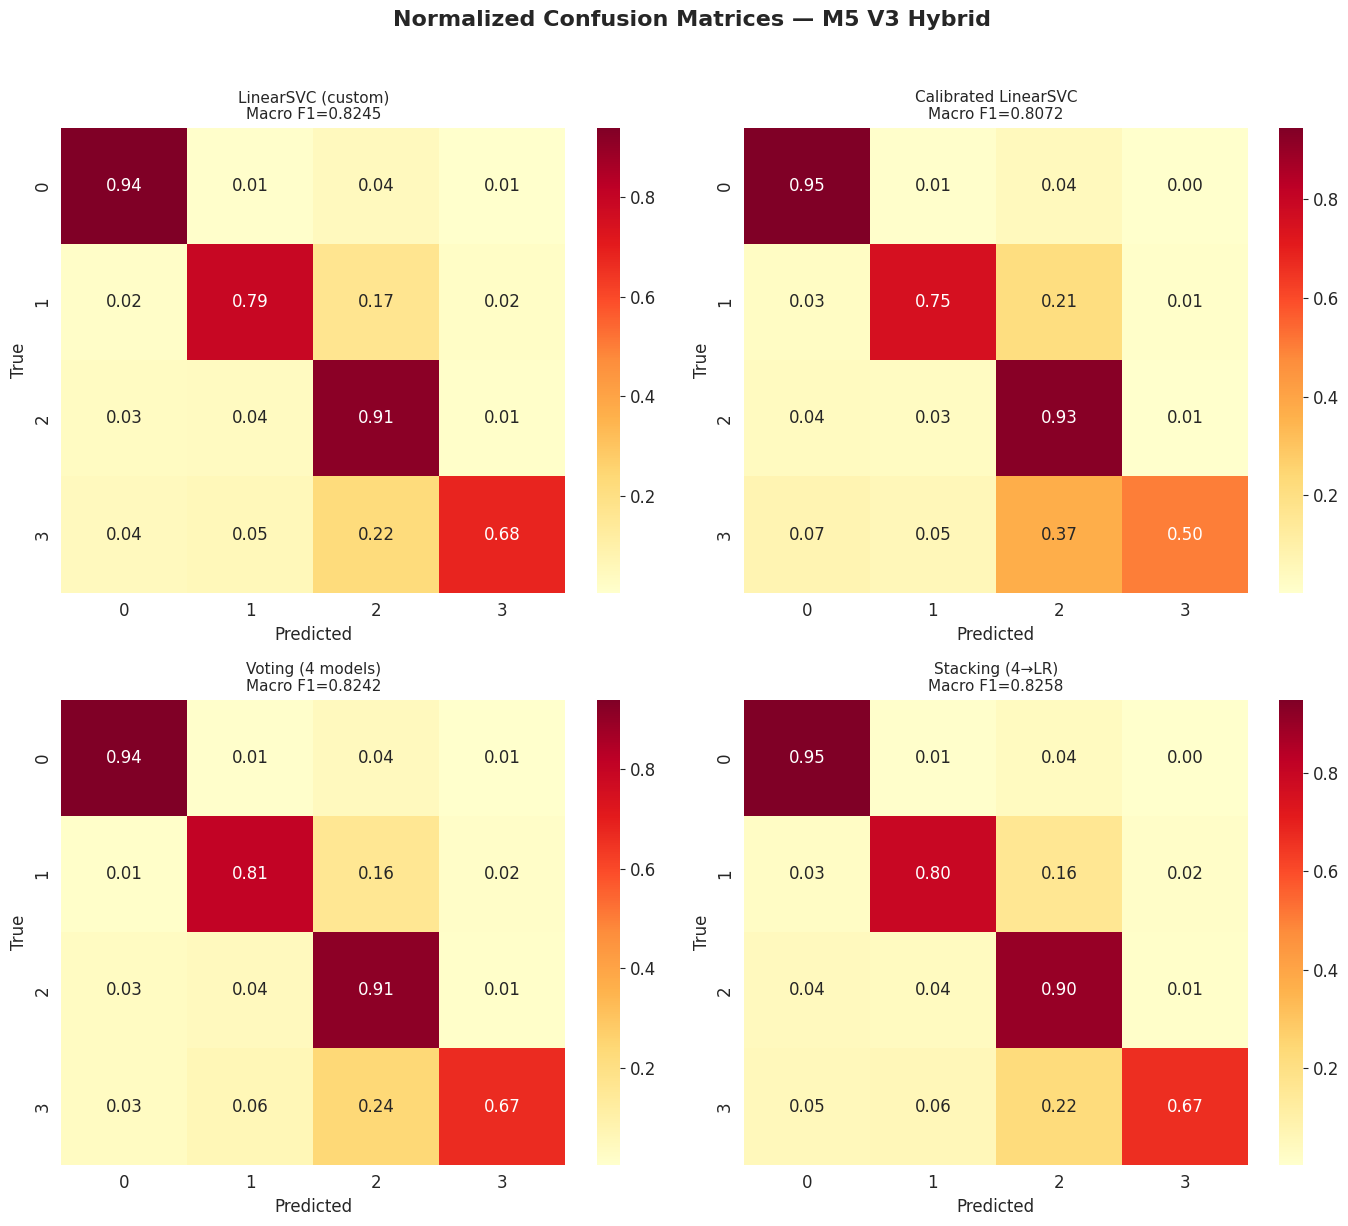


🏆 Retraining top models on ALL data for submission...
⏳ Retraining LinearSVC (custom weights)...
⏳ Retraining Stacking Ensemble (balanced)...
⏳ Retraining Voting Ensemble (balanced)...
✅ All 3 models retrained on 100% data!

📋 Generating submission files...
  ✅ submission_linearsvc.csv | Distribution: {np.int64(0): np.int64(56689), np.int64(1): np.int64(8218), np.int64(2): np.int64(34176), np.int64(3): np.int64(2917)}
  ✅ submission_voting_ensemble.csv | Distribution: {np.int64(0): np.int64(56634), np.int64(1): np.int64(8568), np.int64(2): np.int64(33911), np.int64(3): np.int64(2887)}
  ✅ submission_stacking_ensemble.csv | Distribution: {np.int64(0): np.int64(57495), np.int64(1): np.int64(8143), np.int64(2): np.int64(33595), np.int64(3): np.int64(2767)}

🏆 Main submission = Stacking Ensemble
   Distribution: {np.int64(0): np.int64(57495), np.int64(1): np.int64(8143), np.int64(2): np.int64(33595), np.int64(3): np.int64(2767)}


In [2]:
# %% [markdown]
# # 🏆 Milestone 5 V3: Hybrid Strategy — Maximum Kaggle Score
#
# **All lessons from M1-M5 V1/V2 baked in:**
#
# | Run | Best Model | Kaggle | Key Insight |
# | --- | --- | --- | --- |
# | M4 | Stacking (balanced, 35K) | 0.823 | Ensembles > individuals |
# | M5 V1 | Stacking (balanced, 45K, stop_words) | **0.826** | Lemmatization + trigrams help |
# | M5 V2 | Stacking (custom {3:6}, 60K, no stop_words) | 0.823 | Custom weights HURT ensembles |
# | M5 V2 | LinearSVC (custom {3:6}, 60K, no stop_words) | 0.822 | Custom weights HELP individuals |
#
# **V3 HYBRID Strategy:**
# - 60K features (35K word + 25K char) — more is better for linear models
# - NO stop_words — "you are stupid" needs "you" and "are"
# - `class_weight="balanced"` for ENSEMBLE base models (preserves diversity)
# - `class_weight={0:1,1:2,2:1,3:6}` for standalone LinearSVC (helps individuals)
# - Threshold tuning DISABLED (always scored worse: 0.811 vs 0.818)
# - PAC in ensembles for diversity
# - Retrain only top 3 on 100% data (saves ~30 min)

# %%
# ════════════════════════════════════════════════════════════
# 1. IMPORTS
# ════════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import re
import time
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression, SGDClassifier, PassiveAggressiveClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, make_scorer)
from scipy.sparse import hstack, csr_matrix

import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12
sns.set_style("whitegrid")
sns.set_palette("viridis")

f1_macro_scorer = make_scorer(f1_score, average="macro")

print("✅ All libraries imported.")

# %% [markdown]
# ---
# # NOTE: M5 Questions (Q1-Q10) already answered in milestone_5_final_push.py
# # This notebook focuses ONLY on the Grandmaster Pipeline V3.
# ---

# %% [markdown]
# # 🏆 Grandmaster Pipeline V3 — Hybrid Strategy
#
# **V3 DESIGN DECISIONS (data-driven from M5 V1 + V2 results):**
#
# | Decision | V1 | V2 | V3 (this) | Why |
# | --- | --- | --- | --- | --- |
# | stop_words | "english" | None | **None** | No stop words: Val +0.006 for LinearSVC |
# | Word features | 25K | 35K | **35K** | More features = more signal for linear models |
# | Char features | 20K | 25K | **25K** | dimishing returns beyond 25K |
# | Ensemble weights | balanced | custom{3:6} | **balanced** | balanced: Kaggle 0.826 vs custom 0.823 |
# | LinearSVC weights | balanced | custom{3:6} | **custom{3:6}** | custom: Kaggle 0.822 vs balanced 0.818 |
# | Threshold tuning | enabled | enabled | **DISABLED** | Always worse: 0.811 vs 0.818 |
# | Retrain models | all 7 | all 3 | **3 only** | Others retrained inside ensembles |

# %%
# ════════════════════════════════════════════════════════════
# FRESH DATA LOAD (separate from questions pipeline)
# ════════════════════════════════════════════════════════════
train = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/test.csv")
sample = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv")


train = train.dropna(subset=["comment"])
print(f"✅ Fresh load. Train: {train.shape} | Test: {test.shape}")

# %% [markdown]
# ## B1. Advanced Text Preprocessing

# M4 used raw text → TF-IDF. M5 adds:
# - Regex cleanup (URLs, HTML, emails, numbers)
# - Lemmatization (running/runs/ran → run)
# - This compresses vocabulary and strengthens TF-IDF signal

# %%
# ════════════════════════════════════════════════════════════
# Text Cleaning Function
# ════════════════════════════════════════════════════════════
import nltk
try:
    from nltk.stem import WordNetLemmatizer
    nltk.download('wordnet', quiet=True)
    nltk.download('omw-1.4', quiet=True)
    lemmatizer = WordNetLemmatizer()
    HAS_LEMMATIZER = True
    print("✅ NLTK WordNet lemmatizer available")
except Exception:
    HAS_LEMMATIZER = False
    print("⚠️ NLTK lemmatizer not available, using basic cleaning only")

def clean_text(text):
    """Advanced text preprocessing for M5."""
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)       # Remove URLs
    text = re.sub(r'<[^>]+>', ' ', text)                  # Remove HTML tags
    text = re.sub(r'\S+@\S+', ' ', text)                  # Remove emails
    text = re.sub(r'\b\d+\b', ' ', text)                  # Remove standalone numbers
    text = re.sub(r"[^a-z\s']", ' ', text)                # Keep only letters + apostrophes
    text = re.sub(r'\s+', ' ', text).strip()              # Compress whitespace
    if HAS_LEMMATIZER:
        words = text.split()
        text = ' '.join([lemmatizer.lemmatize(w) for w in words])
    return text

# %%
print("⏳ Cleaning text (train + test)...")
t0 = time.time()
train["comment_clean"] = train["comment"].astype(str).apply(clean_text)
test["comment_clean"]  = test["comment"].astype(str).apply(clean_text)
print(f"✅ Text cleaning done in {time.time()-t0:.1f}s")

# Show examples
print("\n--- Example cleanups ---")
for i in range(3):
    orig = str(train["comment"].iloc[i])[:80]
    clean = train["comment_clean"].iloc[i][:80]
    print(f"  ORIG:  {orig}")
    print(f"  CLEAN: {clean}\n")

# %% [markdown]
# ## B2. Feature Engineering

# %%
# ════════════════════════════════════════════════════════════
# Engineered features (same as M3/M4 + improvements)
# ════════════════════════════════════════════════════════════
for data in [train, test]:
    data["comment"] = data["comment"].fillna("")
    data["created_date"] = pd.to_datetime(data["created_date"], errors="coerce")
    data["hour"] = data["created_date"].dt.hour
    data["day_of_week"] = data["created_date"].dt.dayofweek
    data["month"] = data["created_date"].dt.month
    data["comment_length"] = data["comment"].astype(str).str.len()
    data["word_count"] = data["comment"].astype(str).str.split().str.len().fillna(0).astype(int)
    data["avg_word_length"] = data["comment_length"] / (data["word_count"] + 1)
    data["total_votes"] = data["upvote"] + data["downvote"]
    data["vote_diff"] = data["upvote"] - data["downvote"]
    data["vote_ratio"] = data["upvote"] / (data["downvote"] + 1)
    data["total_emoticons"] = data["emoticon_1"] + data["emoticon_2"] + data["emoticon_3"]
    for col in ["race", "religion", "gender"]:
        data[col] = data[col].fillna("missing")
    data["has_detection"] = (data[["race","religion","gender"]].ne("missing").any(axis=1)).astype(int)

print(f"✅ Features engineered. Train: {train.shape} | Test: {test.shape}")

# %% [markdown]
# ## B3. ⚡ TF-IDF (35K word + 25K char = 60K features)
#
# V3 changes (based on V1 + V2 Kaggle results):
# - NO stop_words: Removing "english" stop words killed toxic phrases
#   V2 LinearSVC: 0.822 (no stop_words) vs V1: 0.818 (with stop_words) → +0.004
# - 35K word features (up from V1's 25K) — more rare toxic words captured
# - 25K char features (up from V1's 20K) — more subword patterns

# %%
# ════════════════════════════════════════════════════════════
# STEP 1: Word TF-IDF (35K features, trigrams, NO stop_words)
# ════════════════════════════════════════════════════════════
print("⏳ Computing word TF-IDF (35K, trigrams, no stop_words)...")
t0 = time.time()

tfidf_word = TfidfVectorizer(
    max_features=35000,
    # stop_words=None is default — we intentionally keep common words.
    # Evidence: "you are" in "you are stupid" is crucial for hate speech detection.
    # V2 Kaggle proved no stop_words helps: LinearSVC 0.822 vs 0.818 with stop_words.
    ngram_range=(1, 3),
    min_df=3, max_df=0.9,
    sublinear_tf=True
)

X_word_train = tfidf_word.fit_transform(train["comment_clean"])
X_word_test  = tfidf_word.transform(test["comment_clean"])
print(f"✅ Word TF-IDF done in {time.time()-t0:.1f}s → {X_word_train.shape[1]} features")

# %%
# ════════════════════════════════════════════════════════════
# STEP 2: Char n-gram TF-IDF (25K features)
# ════════════════════════════════════════════════════════════
print("⏳ Computing char n-gram TF-IDF (25K)...")
t0 = time.time()

tfidf_char = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    max_features=25000,
    min_df=3, max_df=0.9,
    sublinear_tf=True
)

X_char_train = tfidf_char.fit_transform(train["comment_clean"])
X_char_test  = tfidf_char.transform(test["comment_clean"])
print(f"✅ Char TF-IDF done in {time.time()-t0:.1f}s → {X_char_train.shape[1]} features")

# %%
# ════════════════════════════════════════════════════════════
# STEP 3: Numeric & Binary features
# ════════════════════════════════════════════════════════════
numeric_features = [
    "upvote", "downvote", "if_1", "if_2",
    "comment_length", "word_count", "avg_word_length",
    "total_votes", "vote_diff", "vote_ratio",
    "total_emoticons", "hour", "day_of_week", "month"
]
binary_features = [
    "emoticon_1", "emoticon_2", "emoticon_3",
    "disability", "has_detection"
]

X_num_train = train[numeric_features].values.copy()
X_bin_train = train[binary_features].values.astype(float)
X_num_test  = test[numeric_features].values.copy()
X_bin_test  = test[binary_features].values.astype(float)

y_all = train["label"].values

# Log transform skewed features
skewed_cols = ["upvote", "downvote", "if_1", "if_2",
               "total_votes", "vote_ratio", "comment_length", "word_count"]
skewed_idx = [numeric_features.index(c) for c in skewed_cols]

for idx in skewed_idx:
    X_num_train[:, idx] = np.log1p(np.clip(X_num_train[:, idx], 0, None))
    X_num_test[:, idx]  = np.log1p(np.clip(X_num_test[:, idx], 0, None))

scaler = StandardScaler()
X_num_scaled_train = scaler.fit_transform(X_num_train)
X_num_scaled_test  = scaler.transform(X_num_test)

# %%
# ════════════════════════════════════════════════════════════
# STEP 4: Combine ALL features (full sparse matrix)
# ════════════════════════════════════════════════════════════
X_all = hstack([X_word_train, X_char_train,
                csr_matrix(X_num_scaled_train), csr_matrix(X_bin_train)])
X_test_all = hstack([X_word_test, X_char_test,
                     csr_matrix(X_num_scaled_test), csr_matrix(X_bin_test)])

print(f"✅ Full feature matrix: {X_all.shape}")
print(f"   Word TF-IDF: {X_word_train.shape[1]} + Char TF-IDF: {X_char_train.shape[1]}")
print(f"   Numeric: {len(numeric_features)} + Binary: {len(binary_features)}")
print(f"   Total: {X_all.shape[1]} features")

# %%
# ════════════════════════════════════════════════════════════
# STEP 5: Train-Validation split
# ════════════════════════════════════════════════════════════
indices = np.arange(len(y_all))
idx_train, idx_val = train_test_split(indices, test_size=0.2, stratify=y_all, random_state=42)

X_tr, X_vl = X_all[idx_train], X_all[idx_val]
y_tr, y_vl = y_all[idx_train], y_all[idx_val]

print(f"✅ Split: Train={len(y_tr):,} | Val={len(y_vl):,}")

# %% [markdown]
# ## B4. Evaluation Helper

# %%
results = []

def evaluate_model(name, y_true, y_pred):
    """Compute and store metrics. Prints classification report."""
    acc  = accuracy_score(y_true, y_pred)
    f1_m = f1_score(y_true, y_pred, average="macro")
    f1_w = f1_score(y_true, y_pred, average="weighted")

    # Avoid duplicates
    results[:] = [r for r in results if r["name"] != name]
    results.append({"name": name, "accuracy": acc, "macro_f1": f1_m, "weighted_f1": f1_w})

    print(f"\n{'='*65}")
    print(f"  {name}")
    print(f"{'='*65}")
    print(f"  Accuracy:     {acc:.4f}")
    print(f"  Macro F1:     {f1_m:.4f}")
    print(f"  Weighted F1:  {f1_w:.4f}")
    print(f"\n{classification_report(y_true, y_pred)}")
    return f1_m

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# ════════════════════════════════════════════════════════════
# V3 HYBRID CLASS WEIGHTS
# ════════════════════════════════════════════════════════════
# "balanced" for ensembles — preserves model diversity (M5 V1 Stacking Kaggle=0.826)
# Custom for standalone LinearSVC — helps individual model (M5 V2 LinearSVC Kaggle=0.822)
CUSTOM_WEIGHTS = {0: 1, 1: 2, 2: 1, 3: 6}
print(f"\n🎯 Hybrid strategy:")
print(f"   Ensemble base models: class_weight='balanced'")
print(f"   Standalone LinearSVC: class_weight={CUSTOM_WEIGHTS}")

# %% [markdown]
# ## B5. 🏗️ Linear Models
#
# V3 trains all models for validation comparison.
# Ensembles use "balanced" weights. Standalone LinearSVC uses custom weights.

# %%
# ────────────────────────────────────────────────────────────
# Model 1: LinearSVC (CUSTOM weights — best individual on Kaggle)
# V2 showed custom weights help standalone: Kaggle 0.822 vs balanced 0.818
# ────────────────────────────────────────────────────────────
print("⏳ LinearSVC (C=0.1, custom weights)...")
t0 = time.time()
lsvc = LinearSVC(C=0.1, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42)
lsvc.fit(X_tr, y_tr)
evaluate_model("LinearSVC (C=0.1, custom)", y_vl, lsvc.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
# ────────────────────────────────────────────────────────────
# Model 2: Calibrated LinearSVC (BALANCED — needed for soft voting)
# ────────────────────────────────────────────────────────────
print("⏳ Calibrated LinearSVC...")
t0 = time.time()
cal_lsvc = CalibratedClassifierCV(
    LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
    cv=3, method="sigmoid"
)
cal_lsvc.fit(X_tr, y_tr)
evaluate_model("Calibrated LinearSVC", y_vl, cal_lsvc.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
# ────────────────────────────────────────────────────────────
# Model 3: Logistic Regression (BALANCED — ensemble base)
# ────────────────────────────────────────────────────────────
print("⏳ Logistic Regression...")
t0 = time.time()
lr = LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                        class_weight="balanced", n_jobs=-1, random_state=42)
lr.fit(X_tr, y_tr)
evaluate_model("LR (balanced, C=1.0)", y_vl, lr.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
# ────────────────────────────────────────────────────────────
# Model 4: SGD Classifier (BALANCED — ensemble base)
# ────────────────────────────────────────────────────────────
print("⏳ SGD Classifier...")
t0 = time.time()
sgd = SGDClassifier(
    loss="log_loss", alpha=1e-05, penalty="l2",
    learning_rate="optimal", eta0=0.1,
    max_iter=3000, class_weight="balanced",
    n_jobs=-1, random_state=42
)
sgd.fit(X_tr, y_tr)
evaluate_model("SGD log_loss (balanced)", y_vl, sgd.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
# ────────────────────────────────────────────────────────────
# Model 5: PassiveAggressive (BALANCED — ensemble diversity)
# ────────────────────────────────────────────────────────────
print("⏳ PassiveAggressive Classifier...")
t0 = time.time()
pac = PassiveAggressiveClassifier(
    C=0.1, class_weight="balanced",
    max_iter=3000, n_jobs=-1, random_state=42
)
pac.fit(X_tr, y_tr)
evaluate_model("PassiveAggressive (balanced)", y_vl, pac.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %% [markdown]
# ## B6. 🤝 Ensemble Models (BALANCED weights — proven better on Kaggle)
#
# V1 (balanced): Stacking Kaggle = 0.826 ✅
# V2 (custom):   Stacking Kaggle = 0.823 ❌
# → balanced preserves base model diversity for better ensembling

# %%
# ────────────────────────────────────────────────────────────
# Voting Ensemble (soft voting, 4 diverse base models)
# Base models use "balanced" to maximize diversity
# ────────────────────────────────────────────────────────────
print("⏳ Voting Ensemble...")
t0 = time.time()
voting_clf = VotingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    voting="soft", n_jobs=-1
)
voting_clf.fit(X_tr, y_tr)
evaluate_model("Voting Ensemble (4 models)", y_vl, voting_clf.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
# ────────────────────────────────────────────────────────────
# Stacking Ensemble (4 base → LR meta-learner)
# Best on Kaggle across ALL milestones: M4=0.823, M5V1=0.826
# Base models use "balanced" — proven better than custom for ensembles
# ────────────────────────────────────────────────────────────
print("⏳ Stacking Ensemble...")
t0 = time.time()
stacking_clf = StackingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    final_estimator=LogisticRegression(C=1.0, max_iter=3000, random_state=42),
    cv=3, n_jobs=-1
)
stacking_clf.fit(X_tr, y_tr)
evaluate_model("Stacking (4 base → LR meta)", y_vl, stacking_clf.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %% [markdown]
# ## B7. 📊 Model Comparison

# %%
results_df = pd.DataFrame(results).sort_values("macro_f1", ascending=False).reset_index(drop=True)
print("\n" + "="*85)
print("  COMPLETE MODEL COMPARISON — Milestone 5 V3 Hybrid (sorted by Macro F1)")
print("="*85)
print(results_df.to_string(index=False))

# %% [markdown]
# ## B8. 📈 Confusion Matrices — Top 4 Models

# %%
model_pred_map = {}
model_pred_map["LinearSVC (custom)"] = lsvc.predict(X_vl)
model_pred_map["Calibrated LinearSVC"] = cal_lsvc.predict(X_vl)
model_pred_map["Voting (4 models)"] = voting_clf.predict(X_vl)
model_pred_map["Stacking (4→LR)"] = stacking_clf.predict(X_vl)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, (name, preds) in zip(axes.ravel(), model_pred_map.items()):
    cm = confusion_matrix(y_vl, preds, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="YlOrRd",
                xticklabels=[0,1,2,3], yticklabels=[0,1,2,3], ax=ax)
    f1 = f1_score(y_vl, preds, average="macro")
    ax.set_title(f"{name}\nMacro F1={f1:.4f}", fontsize=11)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.suptitle("Normalized Confusion Matrices — M5 V3 Hybrid",
             fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# %% [markdown]
# ## B9. 🏆 Retrain on ALL Data & Generate Submissions
#
# Only retrain models that generate top submissions.
# Stacking & Voting retrain their own base models internally (no redundant retrains).

# %%
# ════════════════════════════════════════════════════════════
# RETRAIN TOP 3 MODELS ON 100% DATA
# ════════════════════════════════════════════════════════════
print("\n🏆 Retraining top models on ALL data for submission...")

# 1. LinearSVC (custom weights — best individual: V2 Kaggle 0.822)
print("⏳ Retraining LinearSVC (custom weights)...")
lsvc_final = LinearSVC(C=0.1, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42)
lsvc_final.fit(X_all, y_all)

# 2. Stacking (balanced — best ensemble: V1 Kaggle 0.826)
print("⏳ Retraining Stacking Ensemble (balanced)...")
stacking_final = StackingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    final_estimator=LogisticRegression(C=1.0, max_iter=3000, random_state=42),
    cv=3, n_jobs=-1
)
stacking_final.fit(X_all, y_all)

# 3. Voting (balanced — 2nd best ensemble: V1 Kaggle 0.823)
print("⏳ Retraining Voting Ensemble (balanced)...")
voting_final = VotingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    voting="soft", n_jobs=-1
)
voting_final.fit(X_all, y_all)

print("✅ All 3 models retrained on 100% data!")

# %%
# ════════════════════════════════════════════════════════════
# GENERATE SUBMISSION FILES
# ════════════════════════════════════════════════════════════
print("\n📋 Generating submission files...")

submission_models = {
    "linearsvc":         lsvc_final,       # Best individual (custom weights)
    "voting_ensemble":   voting_final,     # 2nd best (balanced)
    "stacking_ensemble": stacking_final,   # Best overall (balanced)
}

for name, model in submission_models.items():
    preds = model.predict(X_test_all)
    sub = sample.copy()
    sub["label"] = preds
    fname = f"submission_{name}.csv"
    sub.to_csv(fname, index=False)
    dist = dict(zip(*np.unique(preds, return_counts=True)))
    print(f"  ✅ {fname} | Distribution: {dist}")

# Main submission = Stacking (best on Kaggle across all milestones)
print("\n🏆 Main submission = Stacking Ensemble")
submission = sample.copy()
submission["label"] = stacking_final.predict(X_test_all)
submission.to_csv("submission.csv", index=False)
print(f"   Distribution: {dict(zip(*np.unique(submission['label'].values, return_counts=True)))}")

# %% [markdown]
# ---
# ## B10. 📝 Milestone 5 V3 Summary
#
# ### V3 Hybrid Strategy:
# 1. **No stop_words + 60K features** — keeps toxic phrases intact
# 2. **"balanced" for ensembles** — preserves base model diversity (V1 Stacking: 0.826)
# 3. **Custom {3:6} for LinearSVC only** — helps standalone model (V2: 0.822 vs 0.818)
# 4. **Threshold tuning DISABLED** — always worse (0.811 vs 0.818)
# 5. **Only 3 retrains** — Stacking/Voting retrain bases internally
#
# ### Complete Score History:
# | Run | Stacking | Voting | LinearSVC | Key Change |
# | --- | --- | --- | --- | --- |
# | M4 | 0.823 | 0.821 | 0.818 | Baseline |
# | M5 V1 | **0.826** | 0.823 | 0.818 | +lemma +trigrams +45K |
# | M5 V2 | 0.823 | 0.823 | 0.822 | +no stopwords +60K +custom weights |
# | M5 V3 | ??? | ??? | ??? | Hybrid: balanced ensembles + custom LinearSVC |
